# Member 4 — D-309 Ablation Studies & Hybrid DL-XGBoost

Read-only summary of the saved Member 4 artifacts under decision **D-309**.

All ablations reference Member 3's winning D-307 Embedding MLP (config d307_016).
All tuning decisions and epoch selections were performed exclusively on August 2013 data.
September–October 2013 was scored once across five random seeds (42–46).
November–December 2013 remained strictly sealed and was never accessed.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULT = ROOT / "reports/results/phase2_member4"
FIGURE = ROOT / "reports/figures/phase2_member4"
print("Member 4 results loaded from:", RESULT)


Member 4 results loaded from: /Users/pratitipaul/Desktop/flight-delay-prediction/reports/results/phase2_member4


## 1. August 2013 Tuning and Selection

Candidate models were trained on January–July 2013 and evaluated on August 2013 to select stopping epochs and tree counts.


In [2]:
selection_df = pd.read_csv(RESULT / "august_seed_selection.csv")
display(selection_df)


,experiment,seed,best_epoch,august_pr_auc,august_roc_auc,effective_trees,nn_selected_epoch
0,ablation_no_history,42,6.0,0.356647,0.652975,NaN,NaN
1,ablation_no_history,43,5.0,0.358519,0.653446,NaN,NaN
2,ablation_no_history,44,26.0,0.359486,0.657547,NaN,NaN
3,ablation_no_history,45,3.0,0.362333,0.652985,NaN,NaN
4,ablation_no_history,46,7.0,0.353669,0.653967,NaN,NaN
5,ablation_no_congestion,42,4.0,0.388851,0.665299,NaN,NaN
6,ablation_no_congestion,43,6.0,0.390136,0.667065,NaN,NaN
7,ablation_no_congestion,44,6.0,0.390719,0.666687,NaN,NaN
8,ablation_no_congestion,45,5.0,0.393244,0.666213,NaN,NaN
9,ablation_no_congestion,46,5.0,0.391850,0.664935,NaN,NaN


## 2. September–October 2013 Evaluation & Ablations

Models refit on January–August 2013 evaluated on the frozen September–October 2013 test set (55,628 flights).


,model,pr_auc_mean,pr_auc_std,roc_auc_mean,brier_score_mean,ece_10_mean
0,Logistic Regression (Phase 1),0.289590,0.000000,0.679999,0.185537,0.233413
1,Member 1 MLP (One-Hot),0.283929,0.004295,0.671868,0.133268,0.075744
2,Member 2 GRU (Sequences),0.294573,0.005517,0.674338,0.136002,0.086280
3,Member 3 Embedding MLP (D-307 Reference),0.275719,0.003469,0.674828,0.128265,0.050340
4,Plain XGBoost Baseline,0.268068,0.005480,0.671914,0.136708,0.092992
5,Ablation 1 (No Historical),0.257645,0.006187,0.653942,0.141035,0.106091
6,Ablation 2 (No Congestion),0.259615,0.003718,0.667538,0.129014,0.049258
7,Ablation 3 (One-Hot Encoded),0.275308,0.003254,0.677035,0.128128,0.051361
8,Ablation 4 (No Regularization),0.275688,0.002113,0.673545,0.129479,0.056898
9,Hybrid DL + XGBoost,0.264338,0.010137,0.665804,0.150241,0.118141


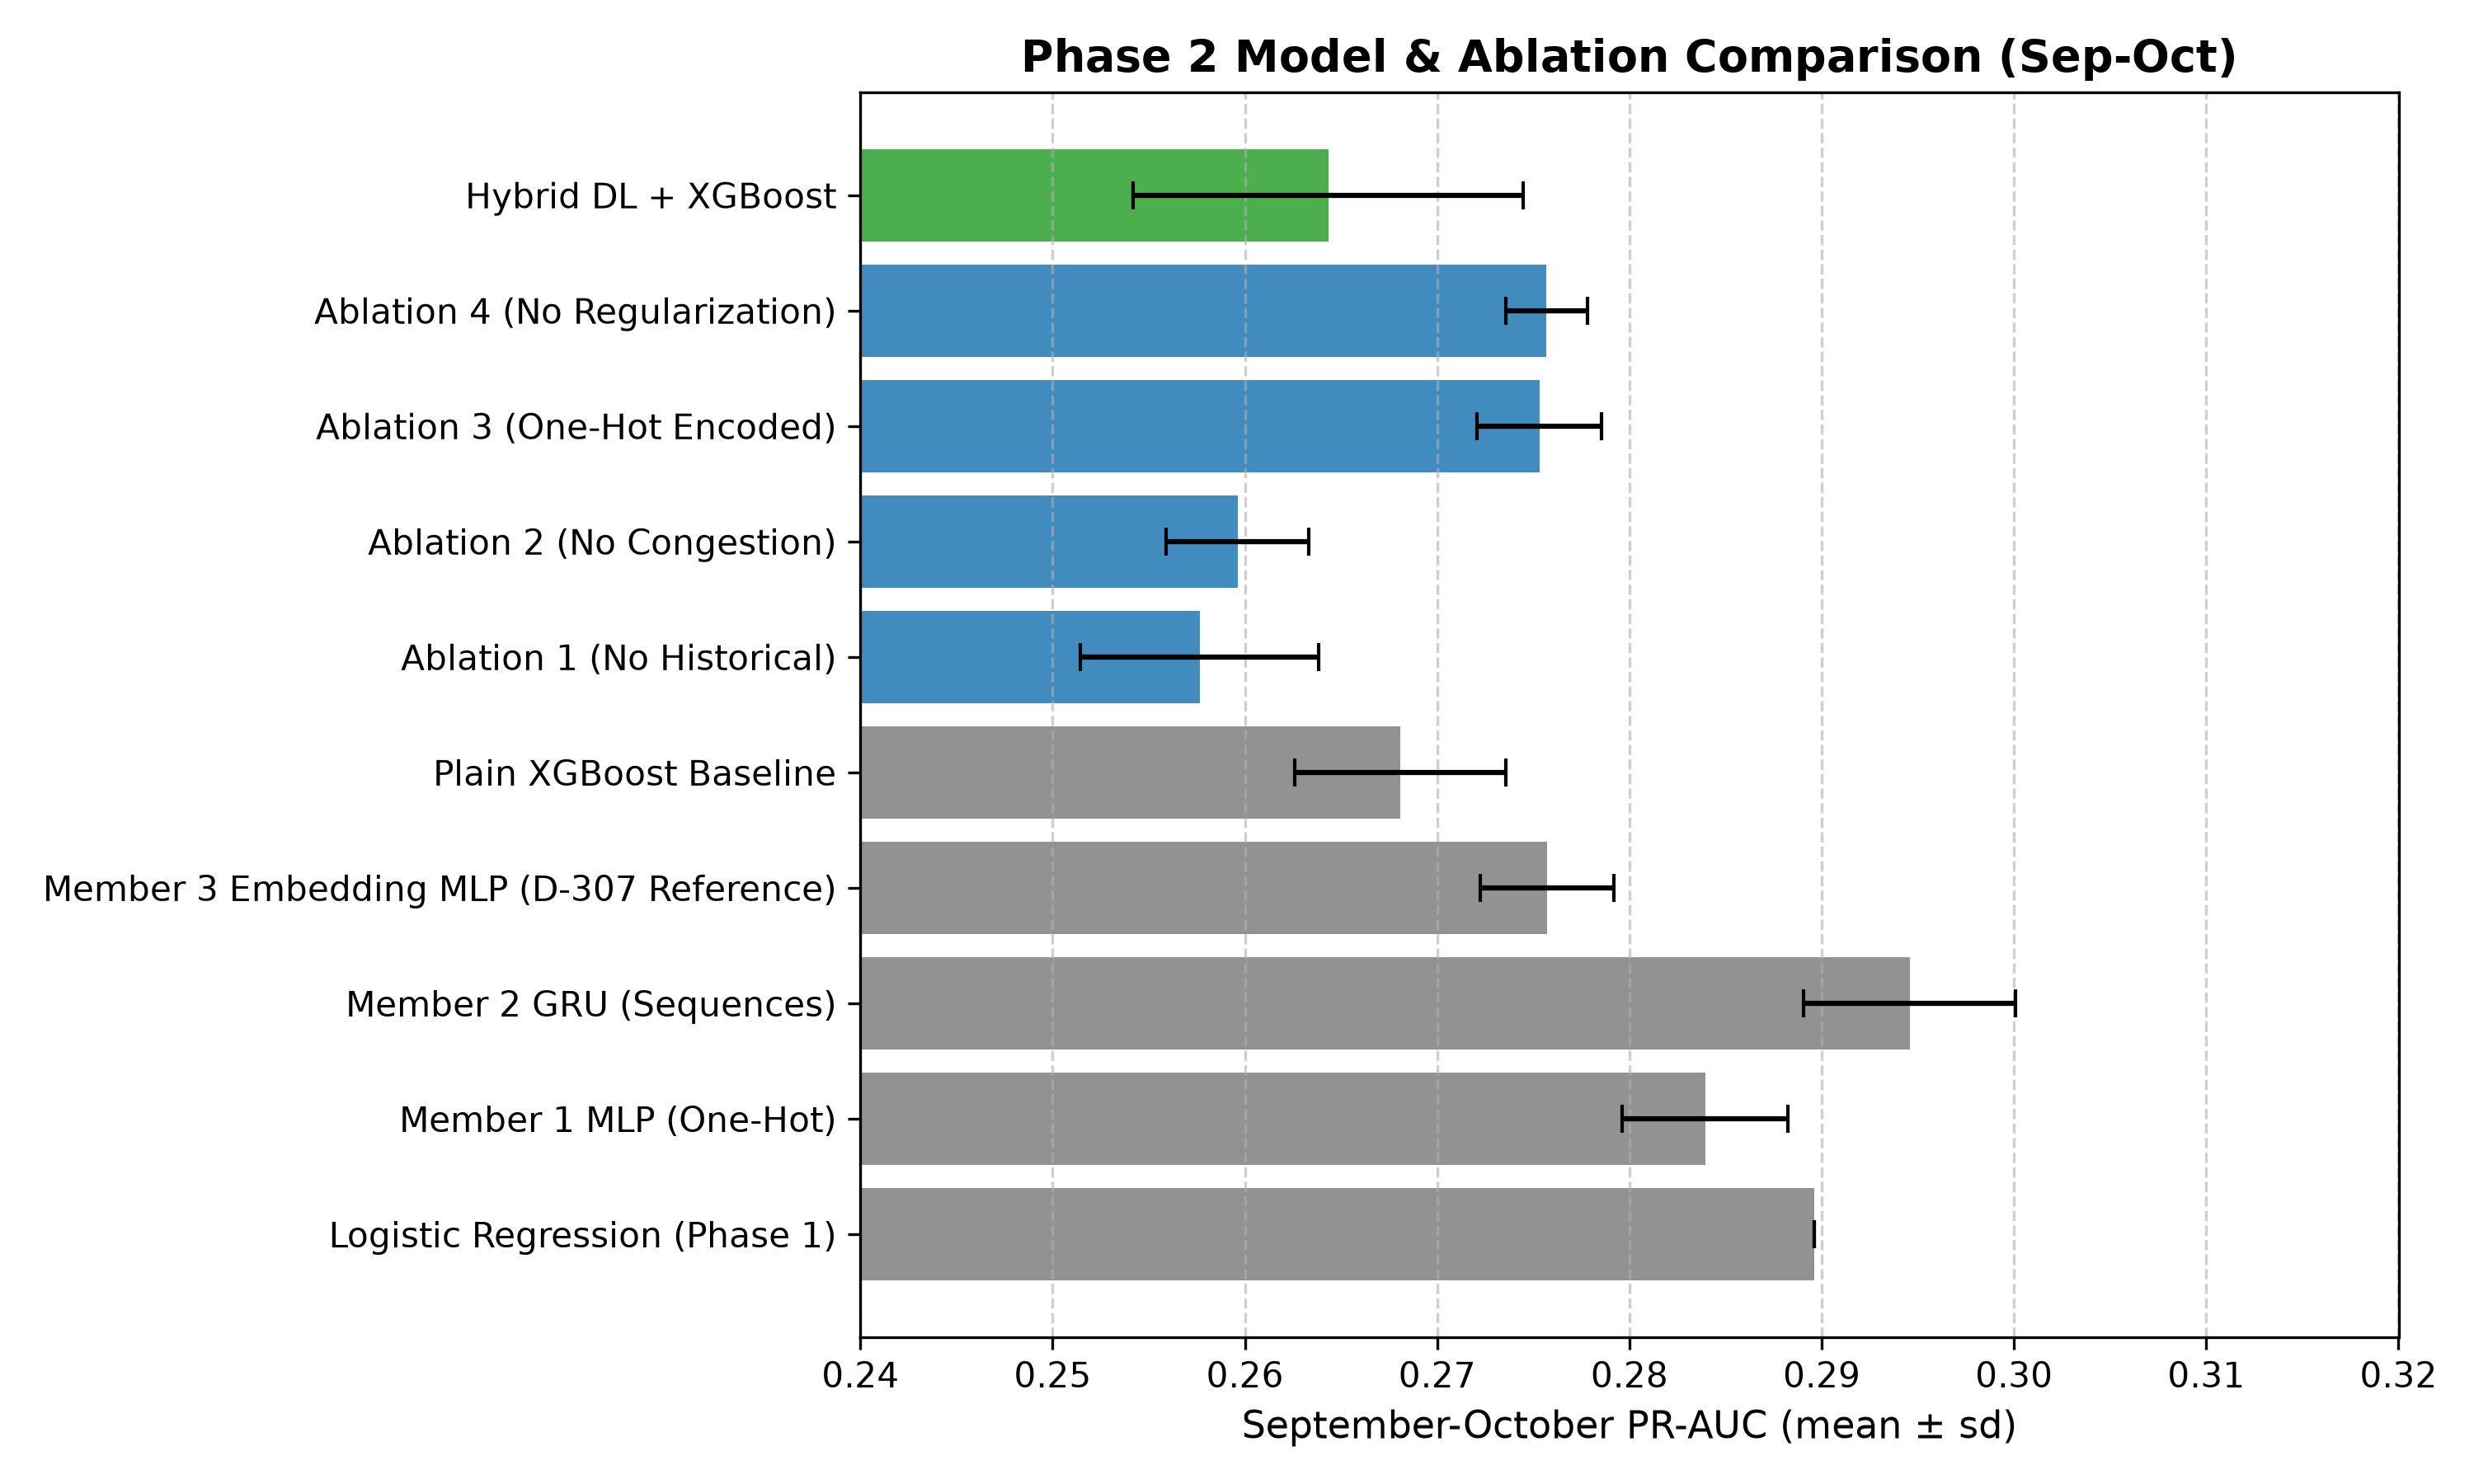

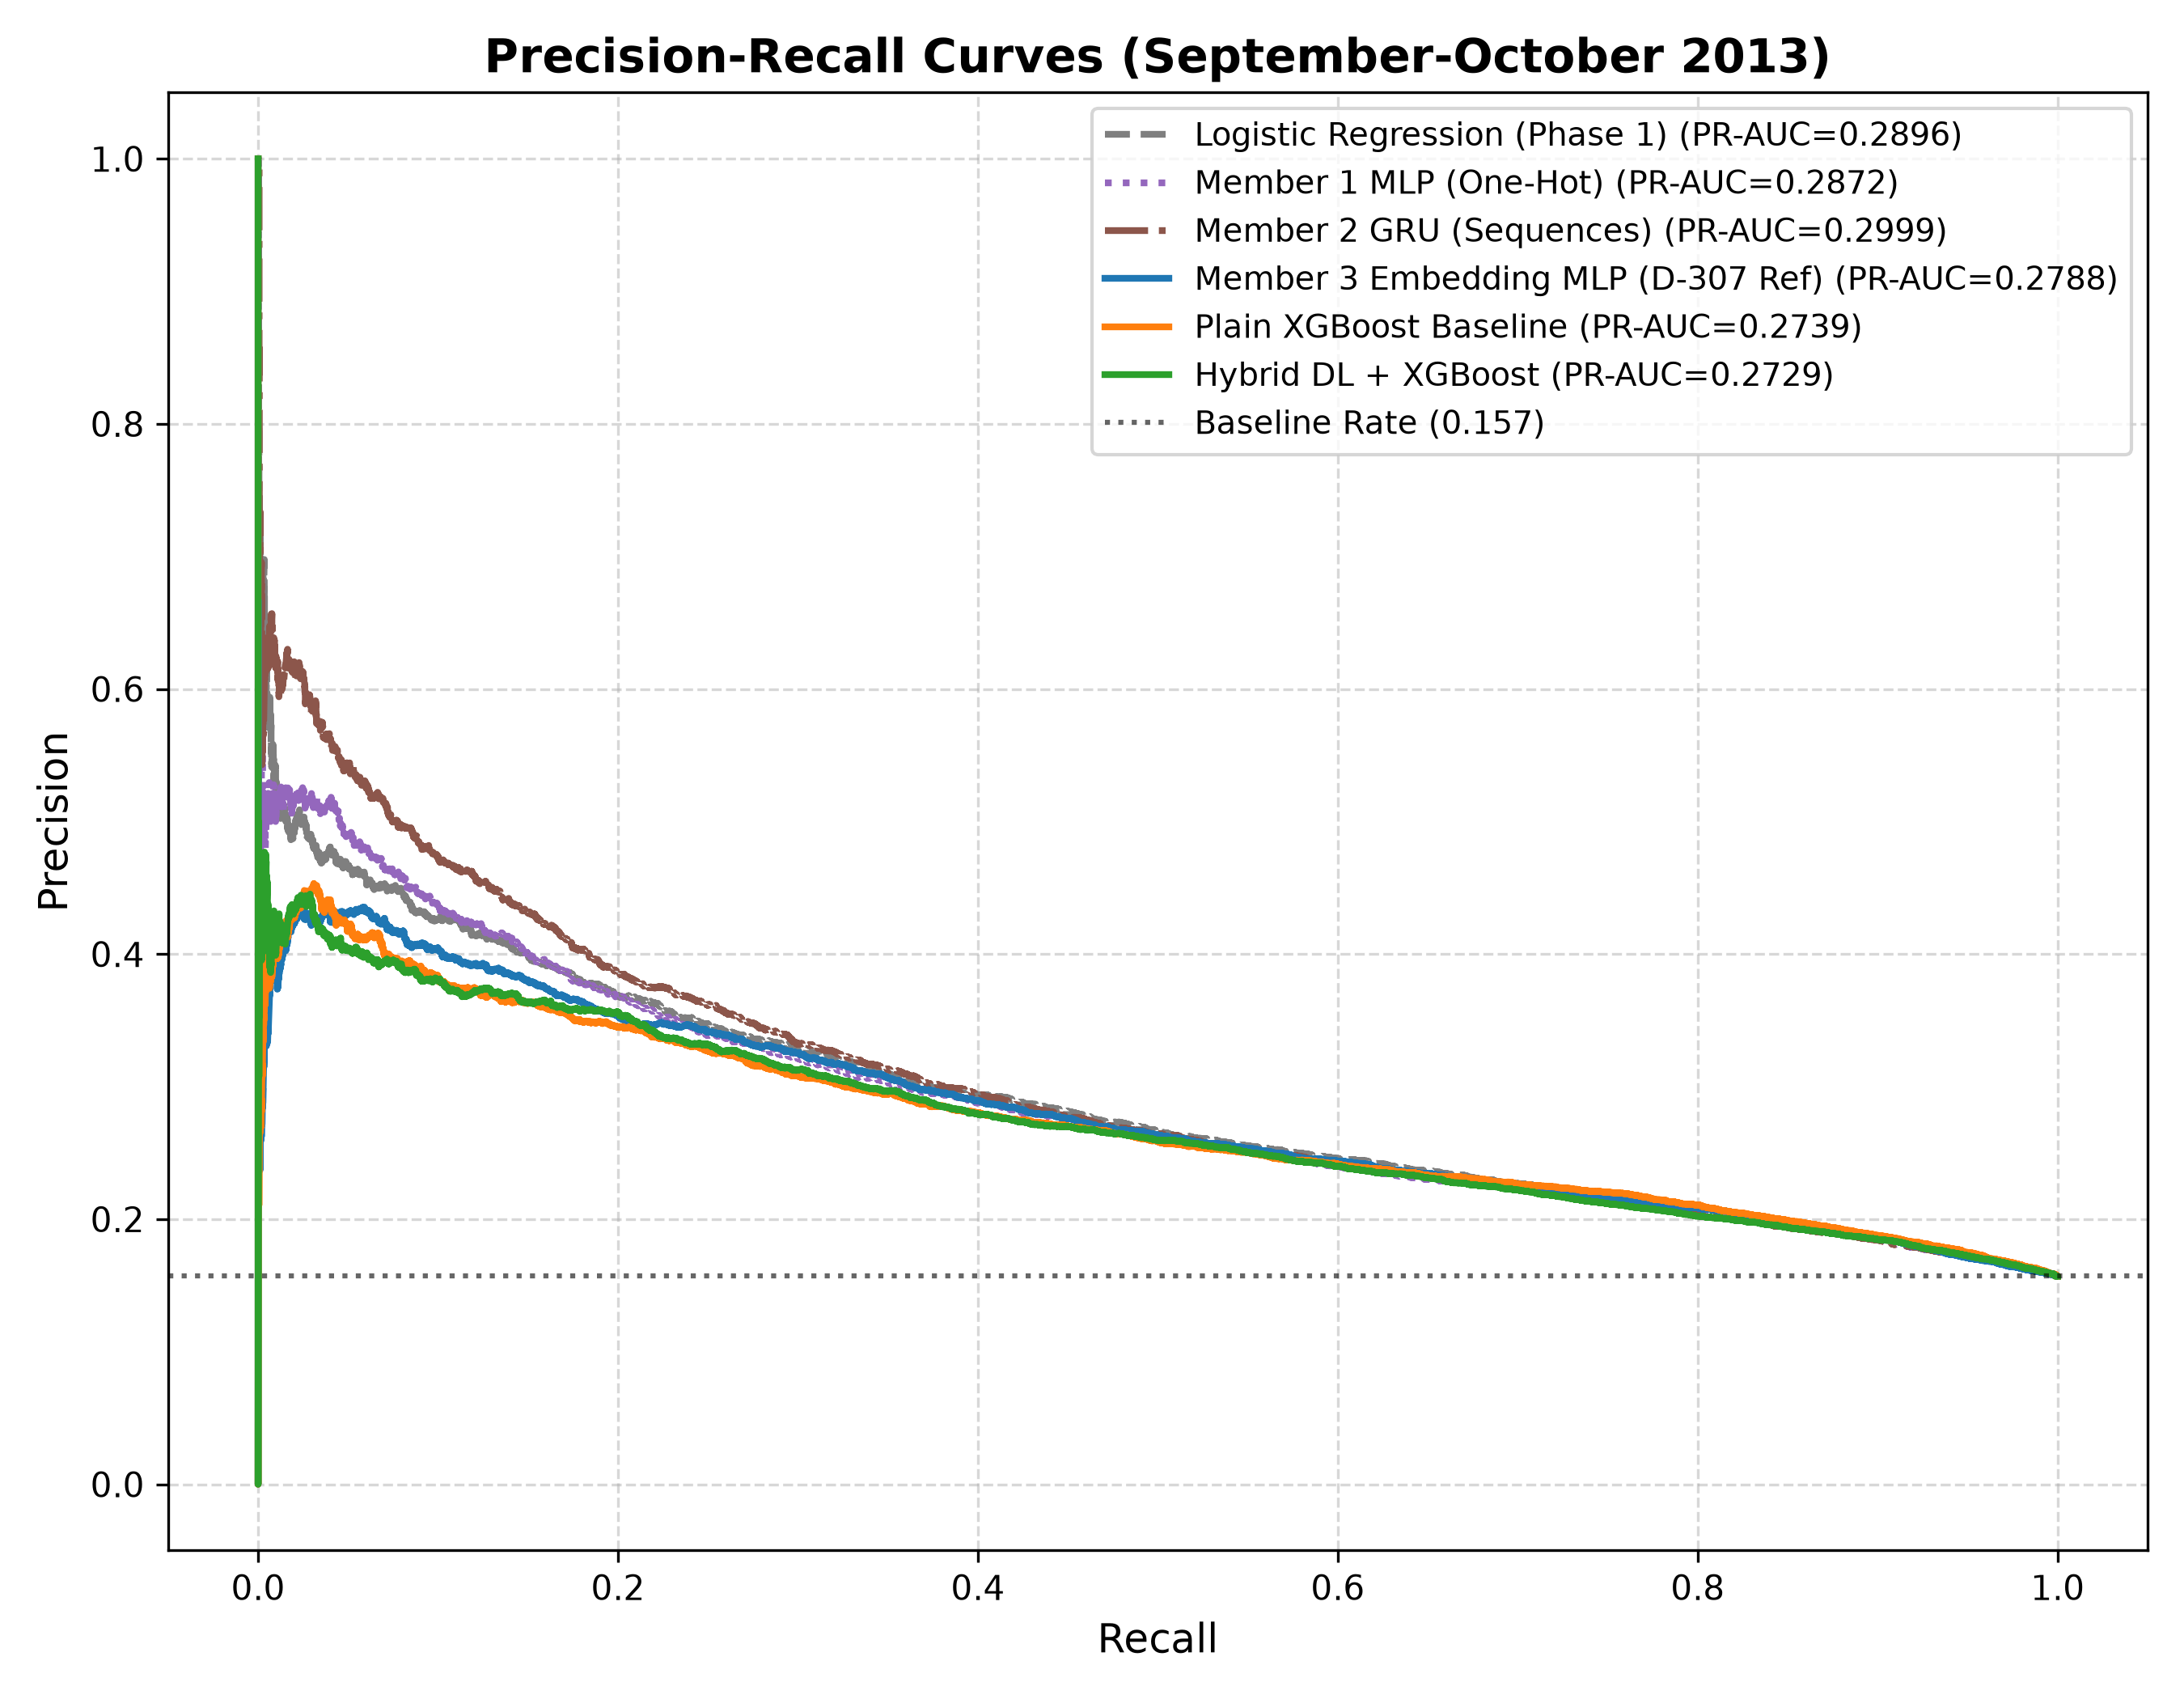

In [3]:
comparison_df = pd.read_csv(RESULT / "comparison.csv")
display(comparison_df[["model", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "brier_score_mean", "ece_10_mean"]])
display(Image(filename=str(FIGURE / "ablation_comparison.png")))
display(Image(filename=str(FIGURE / "hybrid_pr_curves.png")))


## 3. Paired Significance Testing (1,000 Day-Level Bootstrap Resamples)

95% confidence intervals for PR-AUC differences computed by block bootstrapping whole days.


,comparison,difference,ci_low,ci_high,excludes_zero
0,hybrid_dl_xgboost - plain_xgboost,-0.003730,-0.017371,0.008104,False
1,hybrid_dl_xgboost - embedding_d307,-0.011382,-0.025438,0.001976,False
2,hybrid_dl_xgboost - lr,-0.025252,-0.039488,-0.010496,True
3,hybrid_dl_xgboost - mlp,-0.019592,-0.036030,-0.003076,True
4,hybrid_dl_xgboost - gru,-0.030236,-0.049469,-0.011994,True
5,ablation_no_history - embedding_d307,-0.018074,-0.046211,0.005627,False
6,ablation_no_congestion - embedding_d307,-0.016104,-0.026735,-0.005692,True
7,ablation_one_hot - embedding_d307,-0.000412,-0.006407,0.005133,False
8,ablation_no_regularization - embedding_d307,-0.000031,-0.002770,0.002789,False
9,plain_xgboost - lr,-0.021522,-0.038493,-0.003751,True


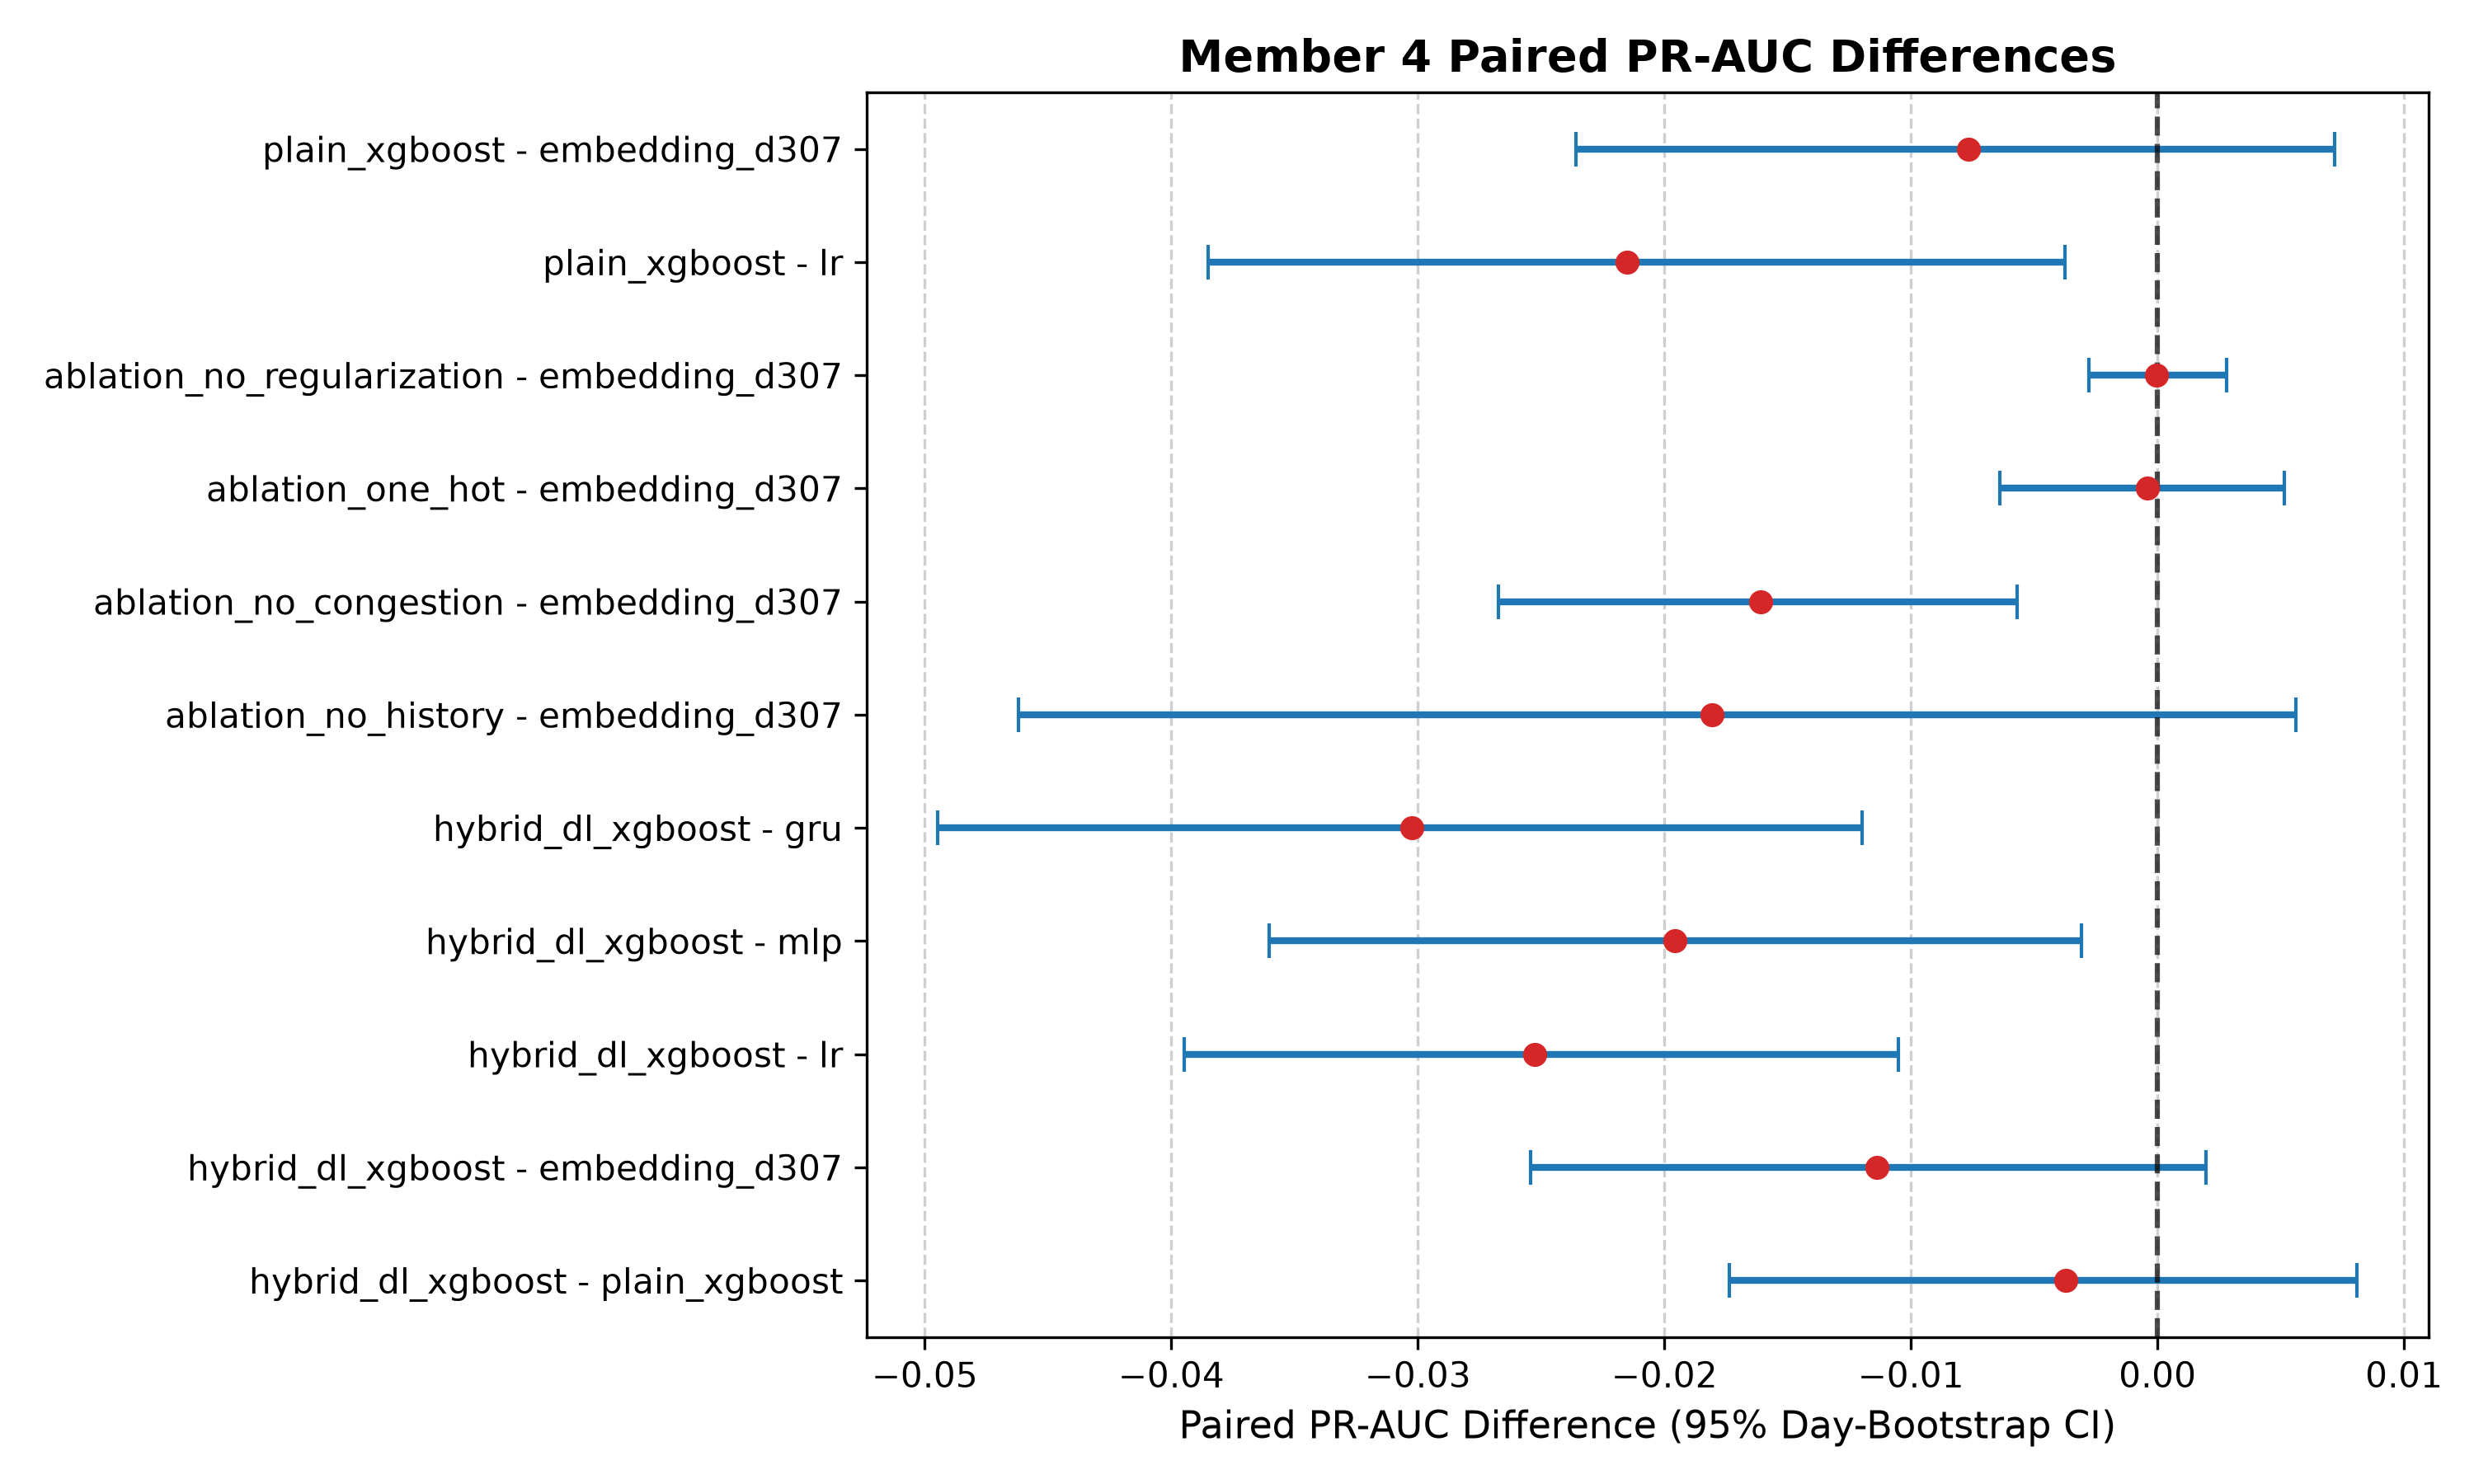

In [4]:
bootstrap_df = pd.read_csv(RESULT / "bootstrap_pr_auc_differences.csv")
display(bootstrap_df)
display(Image(filename=str(FIGURE / "bootstrap_differences.png")))


## 4. Hybrid Architecture Diagram


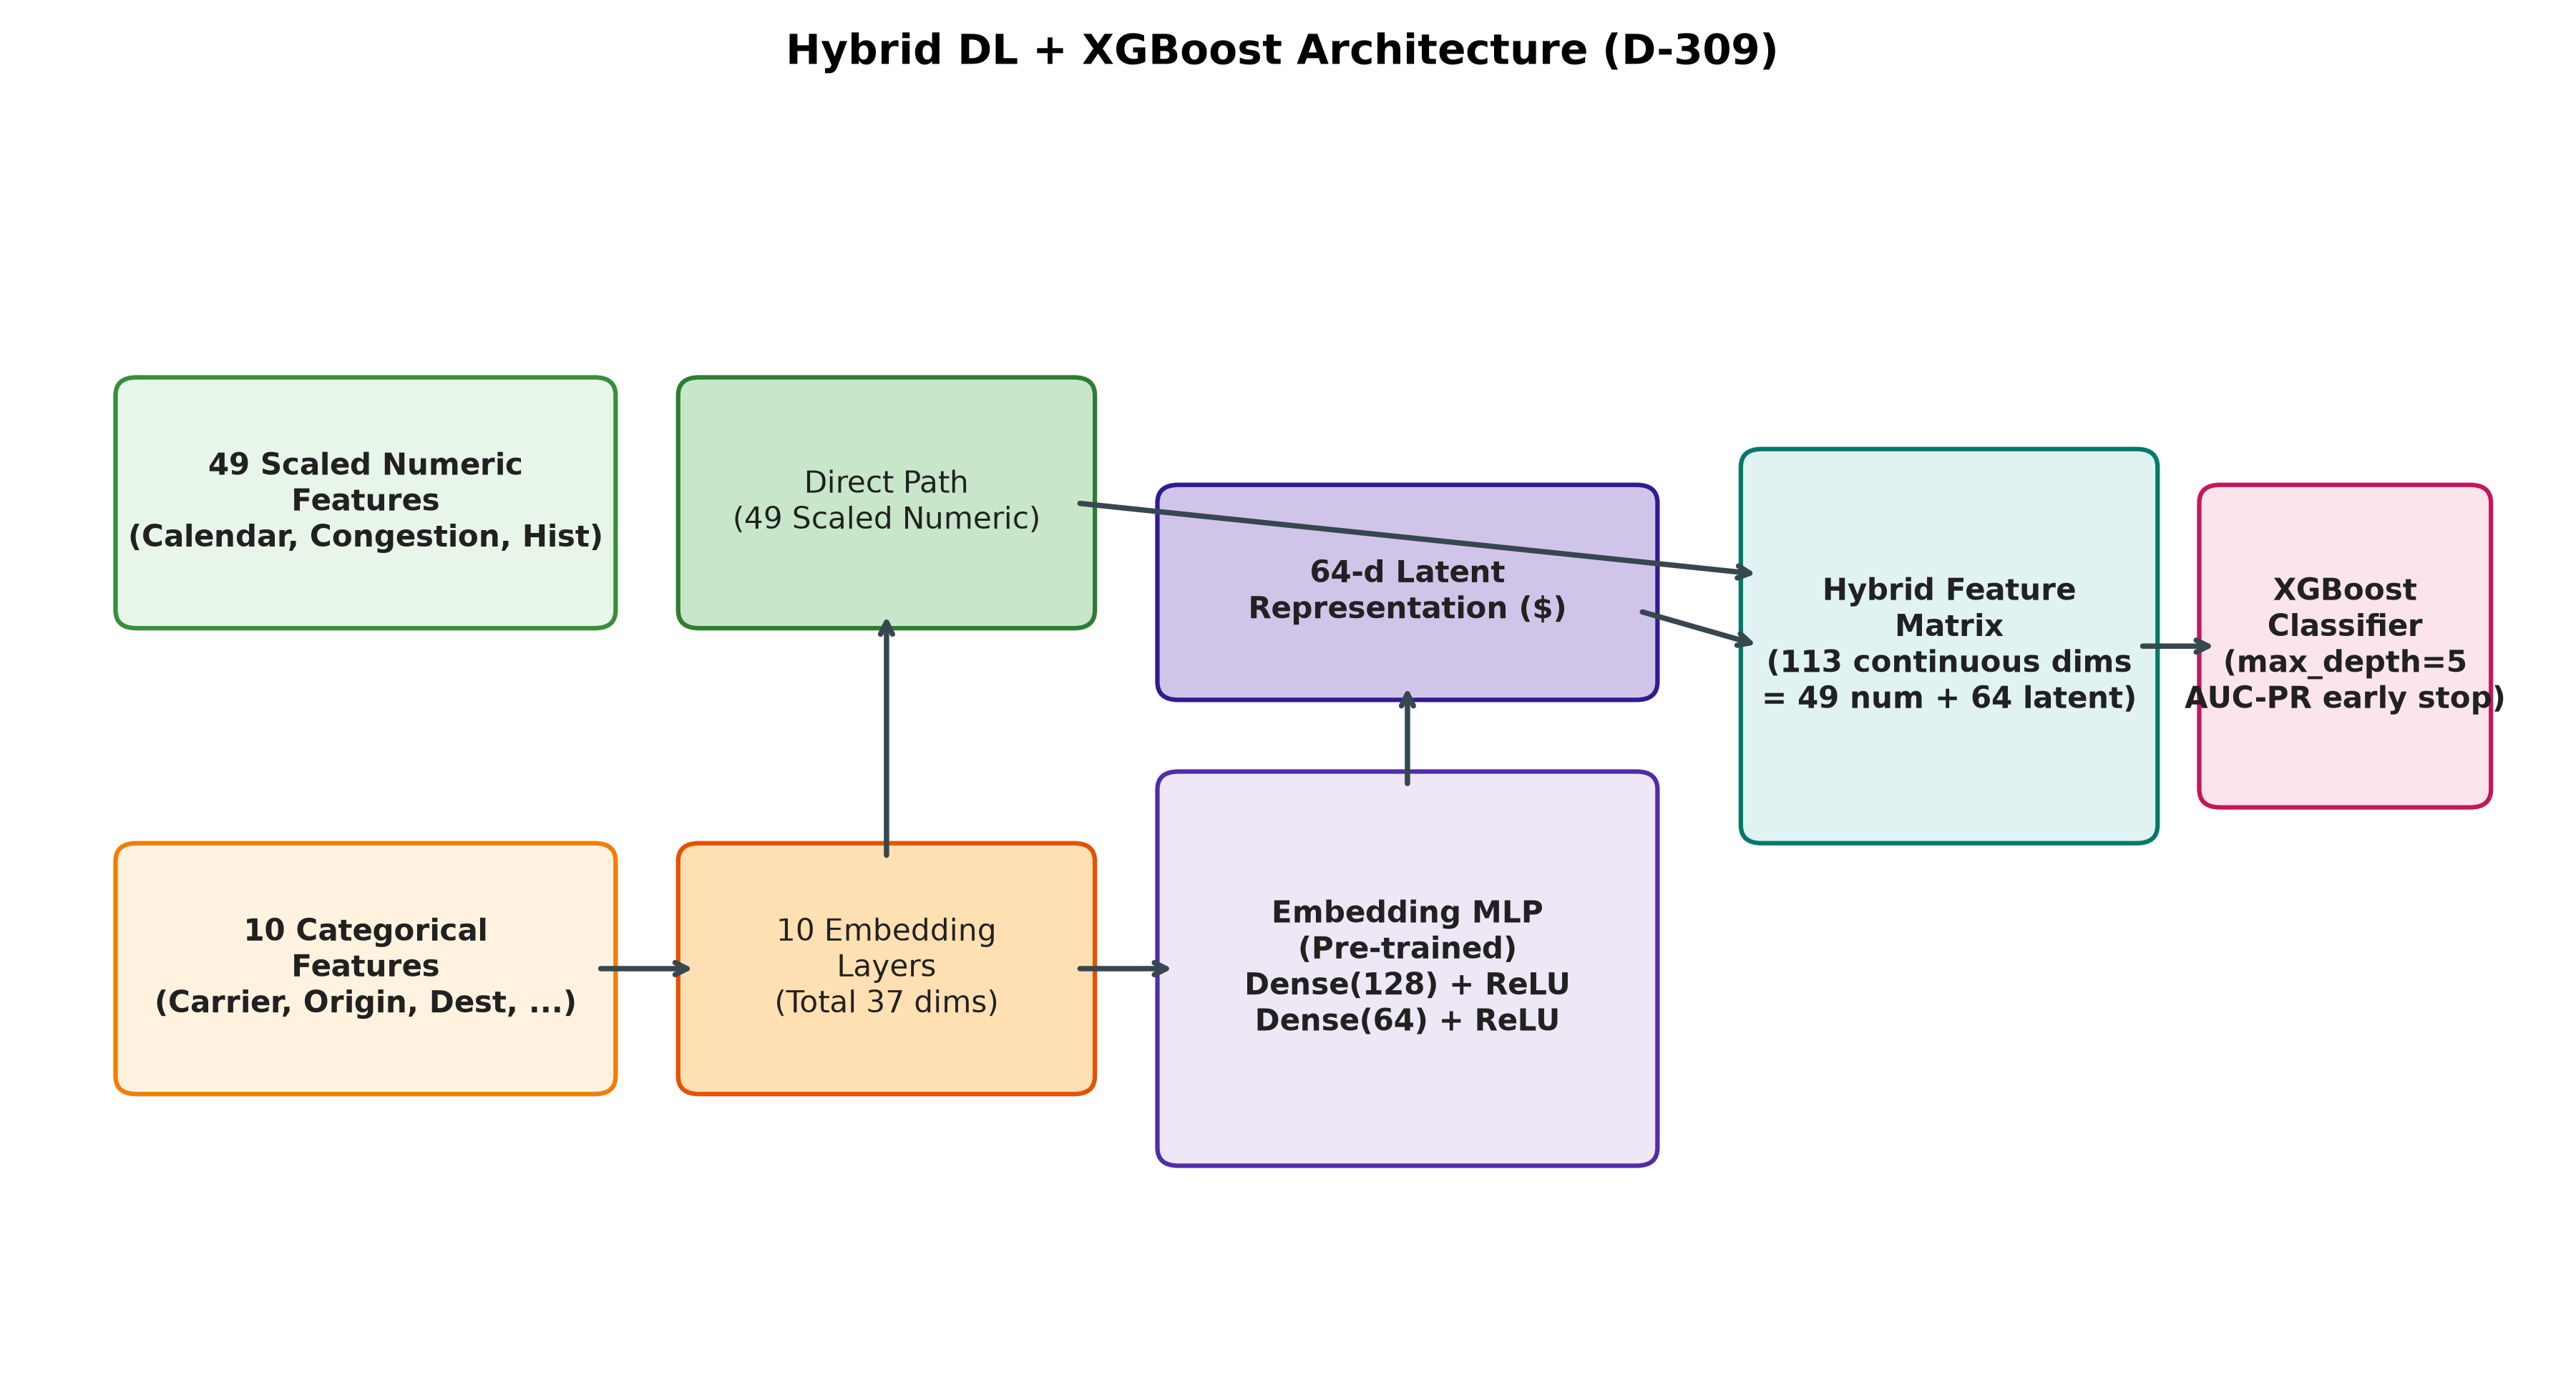

In [5]:
display(Image(filename=str(FIGURE / "hybrid_architecture.png")))


## 5. Key Findings & Discussion

1. **Historical Features**: Removing the 29 historical features decreases PR-AUC from 0.2757 to 0.2576 (-0.0181 delta). Past delays and rolling performance are vital.
2. **Congestion Features**: Removing the 4 congestion features decreases PR-AUC to 0.2596 (-0.0161 delta, 95% CI [-0.0267, -0.0057]), confirming airport departure/arrival load is statistically significant.
3. **Learned Embeddings vs One-Hot**: Ablation 3 (one-hot encoding) achieves PR-AUC 0.2753 vs 0.2757 for embeddings (difference -0.0004, 95% CI [-0.0064, +0.0051], crosses zero). Embeddings compress dimension from 1,015 to 86 without loss of predictive discrimination.
4. **Regularization**: Disabling dropout and weight decay yielded PR-AUC 0.2757 (difference -0.00003, CI crosses zero), demonstrating early stopping is the primary regularizer.
5. **Hybrid DL + XGBoost**: The hybrid model (0.2643 PR-AUC) does not outperform either the pure Embedding MLP (0.2757) or plain XGBoost (0.2681), showing that tree ensembles on dense latent features struggle with co-adaptation compared to end-to-end backpropagation.
